# LAB2 - Bài 6 (Trang 27): Mushroom

Đinh Nhật Huyền Nhân - 6451071055 - CQ.64.CNTT

### Chuẩn bị thư viện và dữ liệu

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

In [2]:
print("Đinh Nhật Huyền Nhân - 6451071055")
data = pd.read_csv('data/mushrooms.csv')
print('Kích thước dữ liệu:', data.shape)
print("Số giá trị '?' trong stalk-root:", (data['stalk-root'] == '?').sum())
data.head()

Đinh Nhật Huyền Nhân - 6451071055
Kích thước dữ liệu: (8124, 23)
Số giá trị '?' trong stalk-root: 2480


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


### Câu 4: Tách thuộc tính bình thường và thuộc tính quyết định

In [3]:
print("Đinh Nhật Huyền Nhân - 6451071055")
features = data.drop('class', axis=1)
labels = data['class']
print('features:', features.shape)
print('labels:', labels.shape)
print(labels.value_counts().sort_index().to_string())

Đinh Nhật Huyền Nhân - 6451071055
features: (8124, 22)
labels: (8124,)
class
e    4208
p    3916


### Câu 5: Chuyển các cột không phải dạng số về one-hot vector

In [4]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Chỉ lấy cột không phải dạng số: np.number bao gồm cả int64 và float64
non_numeric = features.select_dtypes(exclude=[np.number]).columns
print('Các cột không phải dạng số:', list(non_numeric))
features_onehot = pd.get_dummies(features, columns=non_numeric, dtype=int)
print('Kích thước sau khi chuyển đổi:', features_onehot.shape)
features_onehot.head()

Đinh Nhật Huyền Nhân - 6451071055
Các cột không phải dạng số: ['cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor', 'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color', 'stalk-shape', 'stalk-root', 'stalk-surface-above-ring', 'stalk-surface-below-ring', 'stalk-color-above-ring', 'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number', 'ring-type', 'spore-print-color', 'population', 'habitat']
Kích thước sau khi chuyển đổi: (8124, 117)


,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g,cap-surface_s,cap-surface_y,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
0,0,0,0,0,0,1,0,0,1,0,...,1,0,0,0,0,0,0,0,1,0
1,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
2,1,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,1,0,0,0
3,0,0,0,0,0,1,0,0,0,1,...,1,0,0,0,0,0,0,0,1,0
4,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0


**Nhận xét:** Có 22 cột không phải dạng số, sau khi chuyển đổi dữ liệu có 117 cột. Cột stalk-root có 2480 giá trị '?'. Đề chỉ yêu cầu làm từ yêu cầu 4 trở đi, không gồm bước xóa dữ liệu trống, nên '?' được giữ như một giá trị riêng. Cột veil-type chỉ có một giá trị nên không giúp ích cho việc phân lớp.

### Câu 6: Tách dữ liệu huấn luyện và kiểm thử

In [5]:
print("Đinh Nhật Huyền Nhân - 6451071055")
X = features_onehot
y = labels
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print('Number of training data:', len(X_train))
print('Number of test data:', len(X_test))

Đinh Nhật Huyền Nhân - 6451071055
Number of training data: 5686
Number of test data: 2438


**Nhận xét:** Chia theo đúng câu lệnh trong đề: 5686 mẫu huấn luyện (70%) và 2438 mẫu kiểm thử (30%).

### Câu 7: Xây dựng cây ID3 và kiểm thử bằng ma trận nhầm lẫn

In [6]:
print("Đinh Nhật Huyền Nhân - 6451071055")
id3 = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
# Train Decision Tree Classifier
id3.fit(X_train, y_train)
print('Độ sâu của cây:', id3.get_depth(), '- Số nút lá:', id3.get_n_leaves())

Đinh Nhật Huyền Nhân - 6451071055
Độ sâu của cây: 5 - Số nút lá: 11


In [7]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Predict the response for test dataset
id3_pred = id3.predict(X_test)

# Model Accuracy, how often is the classifier correct?
id3_score = metrics.accuracy_score(y_test, id3_pred)
print("Accuracy:", id3_score)
print("Report:", metrics.classification_report(y_test, id3_pred, zero_division=0))

Đinh Nhật Huyền Nhân - 6451071055
Accuracy: 1.0
Report:               precision    recall  f1-score   support

           e       1.00      1.00      1.00      1257
           p       1.00      1.00      1.00      1181

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438



Đinh Nhật Huyền Nhân - 6451071055
[[1257    0]
 [   0 1181]]


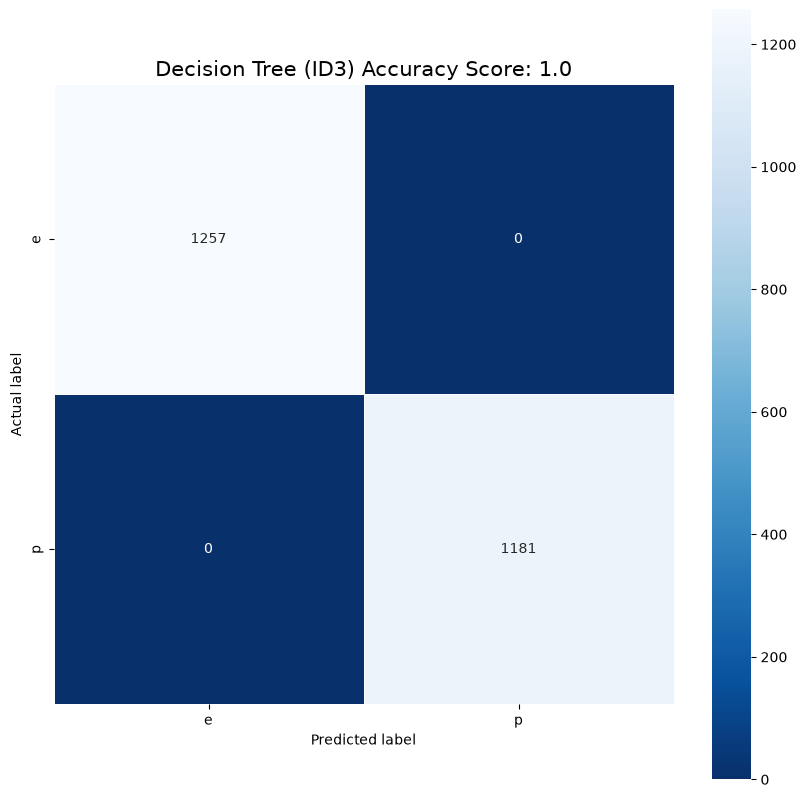

In [8]:
print("Đinh Nhật Huyền Nhân - 6451071055")
id3_cm = metrics.confusion_matrix(y_test, id3_pred, labels=id3.classes_)
print(id3_cm)

plt.figure(figsize=(10, 10))
sns.heatmap(id3_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Blues_r',
            xticklabels=id3.classes_, yticklabels=id3.classes_)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title('Decision Tree (ID3) Accuracy Score: {0}'.format(id3_score), size=15)
plt.show()

Đinh Nhật Huyền Nhân - 6451071055


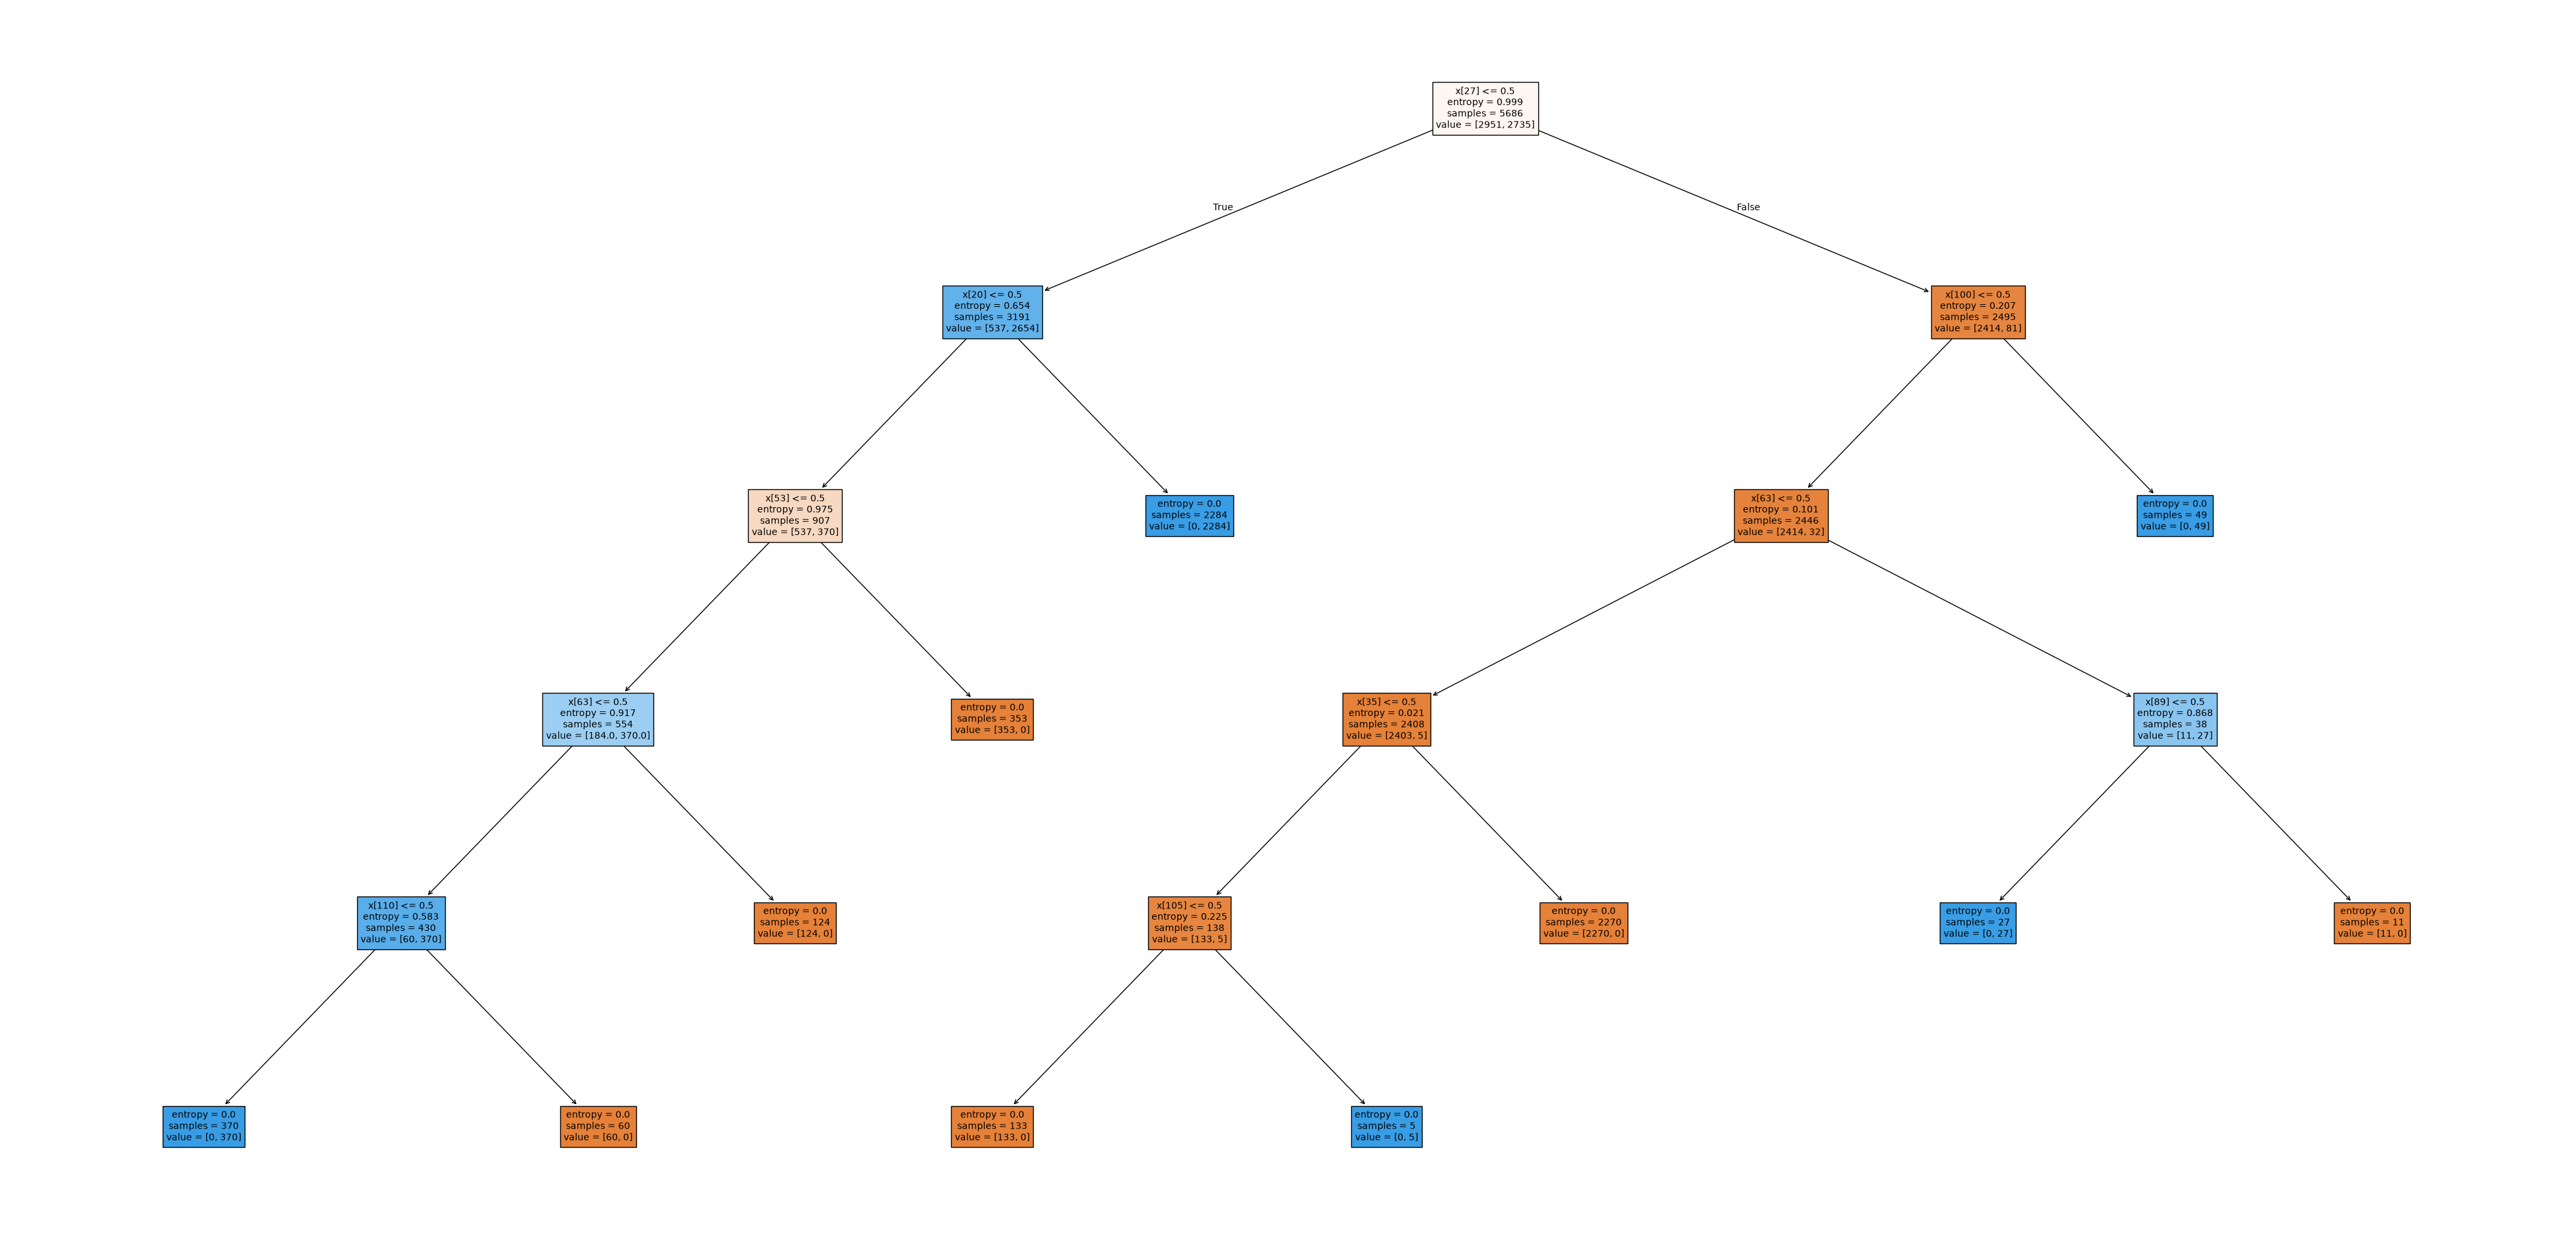

In [9]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Biểu diễn toàn bộ cây và lưu vào file ảnh
fig, ax = plt.subplots(figsize=(50, 24))
tree.plot_tree(id3, filled=True, fontsize=10)
plt.savefig('outputs/bai6_id3_tree', dpi=100)
plt.show()

Đinh Nhật Huyền Nhân - 6451071055


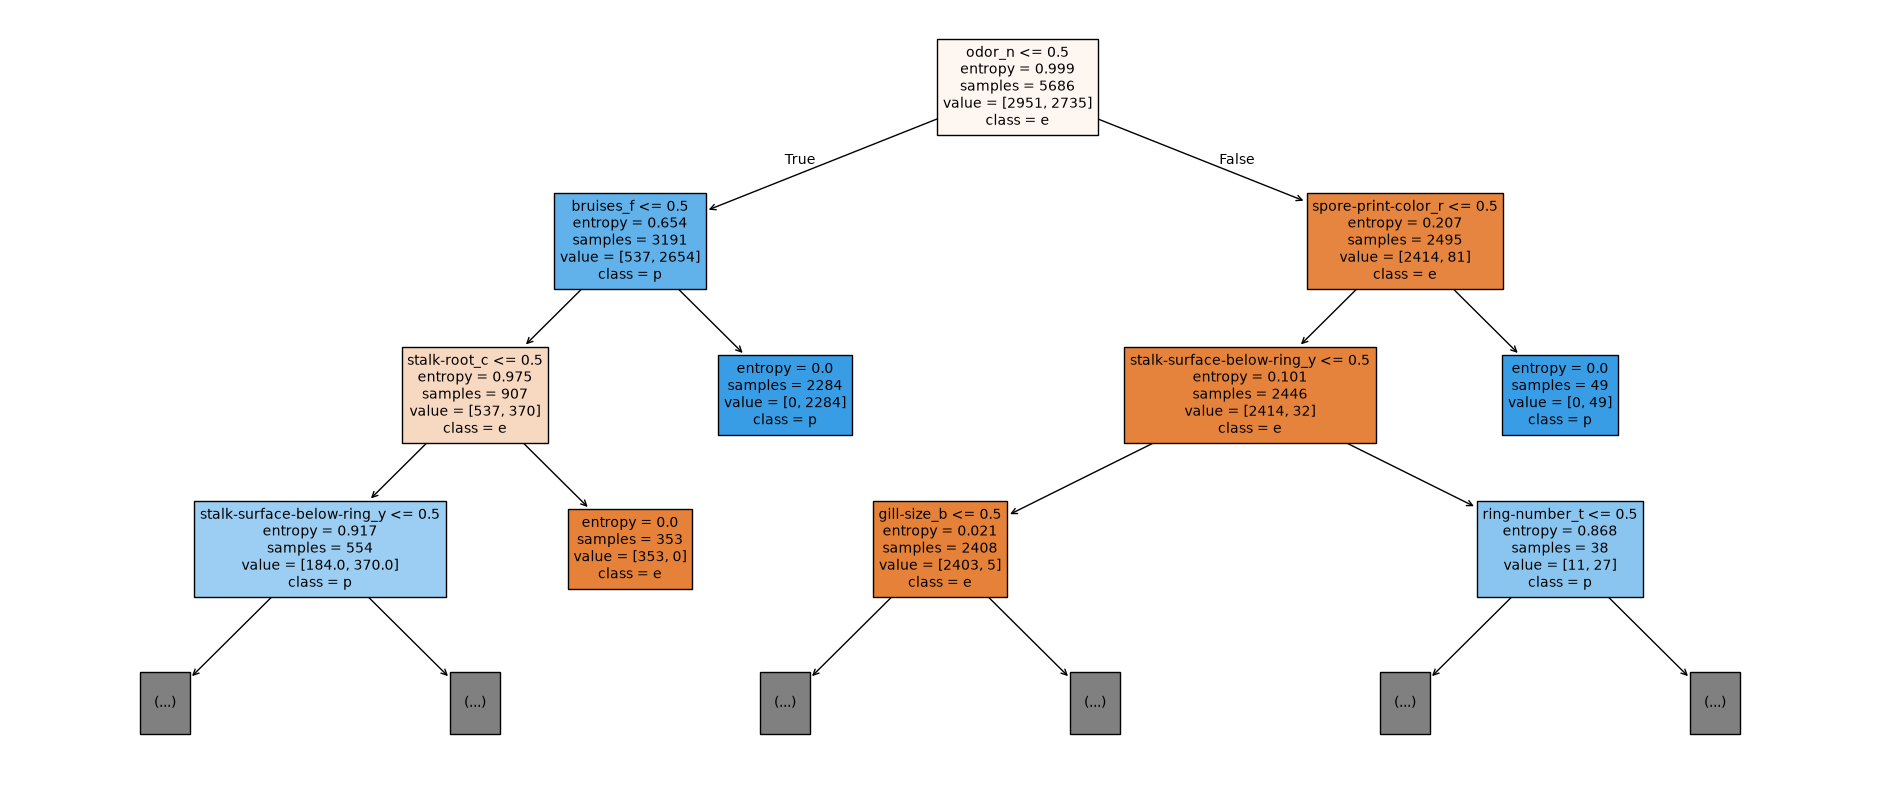

In [10]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Cây đầy đủ rất lớn nên vẽ thêm 3 tầng đầu với tên thuộc tính để dễ đọc
fig, ax = plt.subplots(figsize=(24, 10))
tree.plot_tree(id3, max_depth=3, feature_names=list(X_train.columns),
               class_names=[str(c) for c in id3.classes_], filled=True, fontsize=10)
plt.savefig('outputs/bai6_id3_tree_top3', dpi=100)
plt.show()

### Câu 8: Xây dựng cây CART (criterion='gini')

In [11]:
print("Đinh Nhật Huyền Nhân - 6451071055")
cart = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
# Train Decision Tree Classifier
cart.fit(X_train, y_train)
print('Độ sâu của cây:', cart.get_depth(), '- Số nút lá:', cart.get_n_leaves())

Đinh Nhật Huyền Nhân - 6451071055
Độ sâu của cây: 7 - Số nút lá: 14


In [12]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Predict the response for test dataset
cart_pred = cart.predict(X_test)

# Model Accuracy, how often is the classifier correct?
cart_score = metrics.accuracy_score(y_test, cart_pred)
print("Accuracy:", cart_score)
print("Report:", metrics.classification_report(y_test, cart_pred, zero_division=0))

Đinh Nhật Huyền Nhân - 6451071055
Accuracy: 1.0
Report:               precision    recall  f1-score   support

           e       1.00      1.00      1.00      1257
           p       1.00      1.00      1.00      1181

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438



Đinh Nhật Huyền Nhân - 6451071055
[[1257    0]
 [   0 1181]]


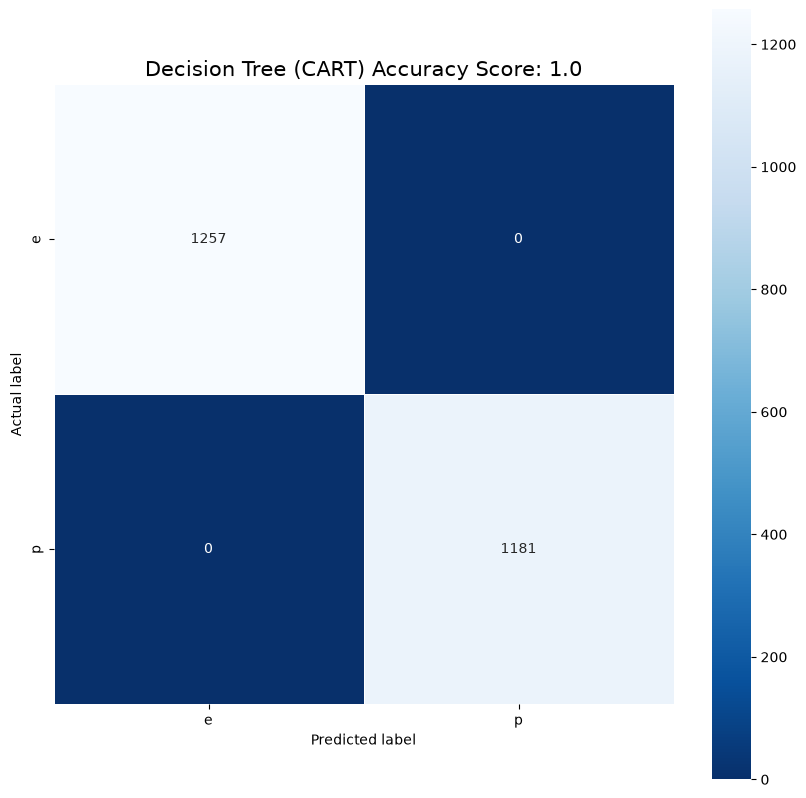

In [13]:
print("Đinh Nhật Huyền Nhân - 6451071055")
cart_cm = metrics.confusion_matrix(y_test, cart_pred, labels=cart.classes_)
print(cart_cm)

plt.figure(figsize=(10, 10))
sns.heatmap(cart_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Blues_r',
            xticklabels=cart.classes_, yticklabels=cart.classes_)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title('Decision Tree (CART) Accuracy Score: {0}'.format(cart_score), size=15)
plt.show()

Đinh Nhật Huyền Nhân - 6451071055


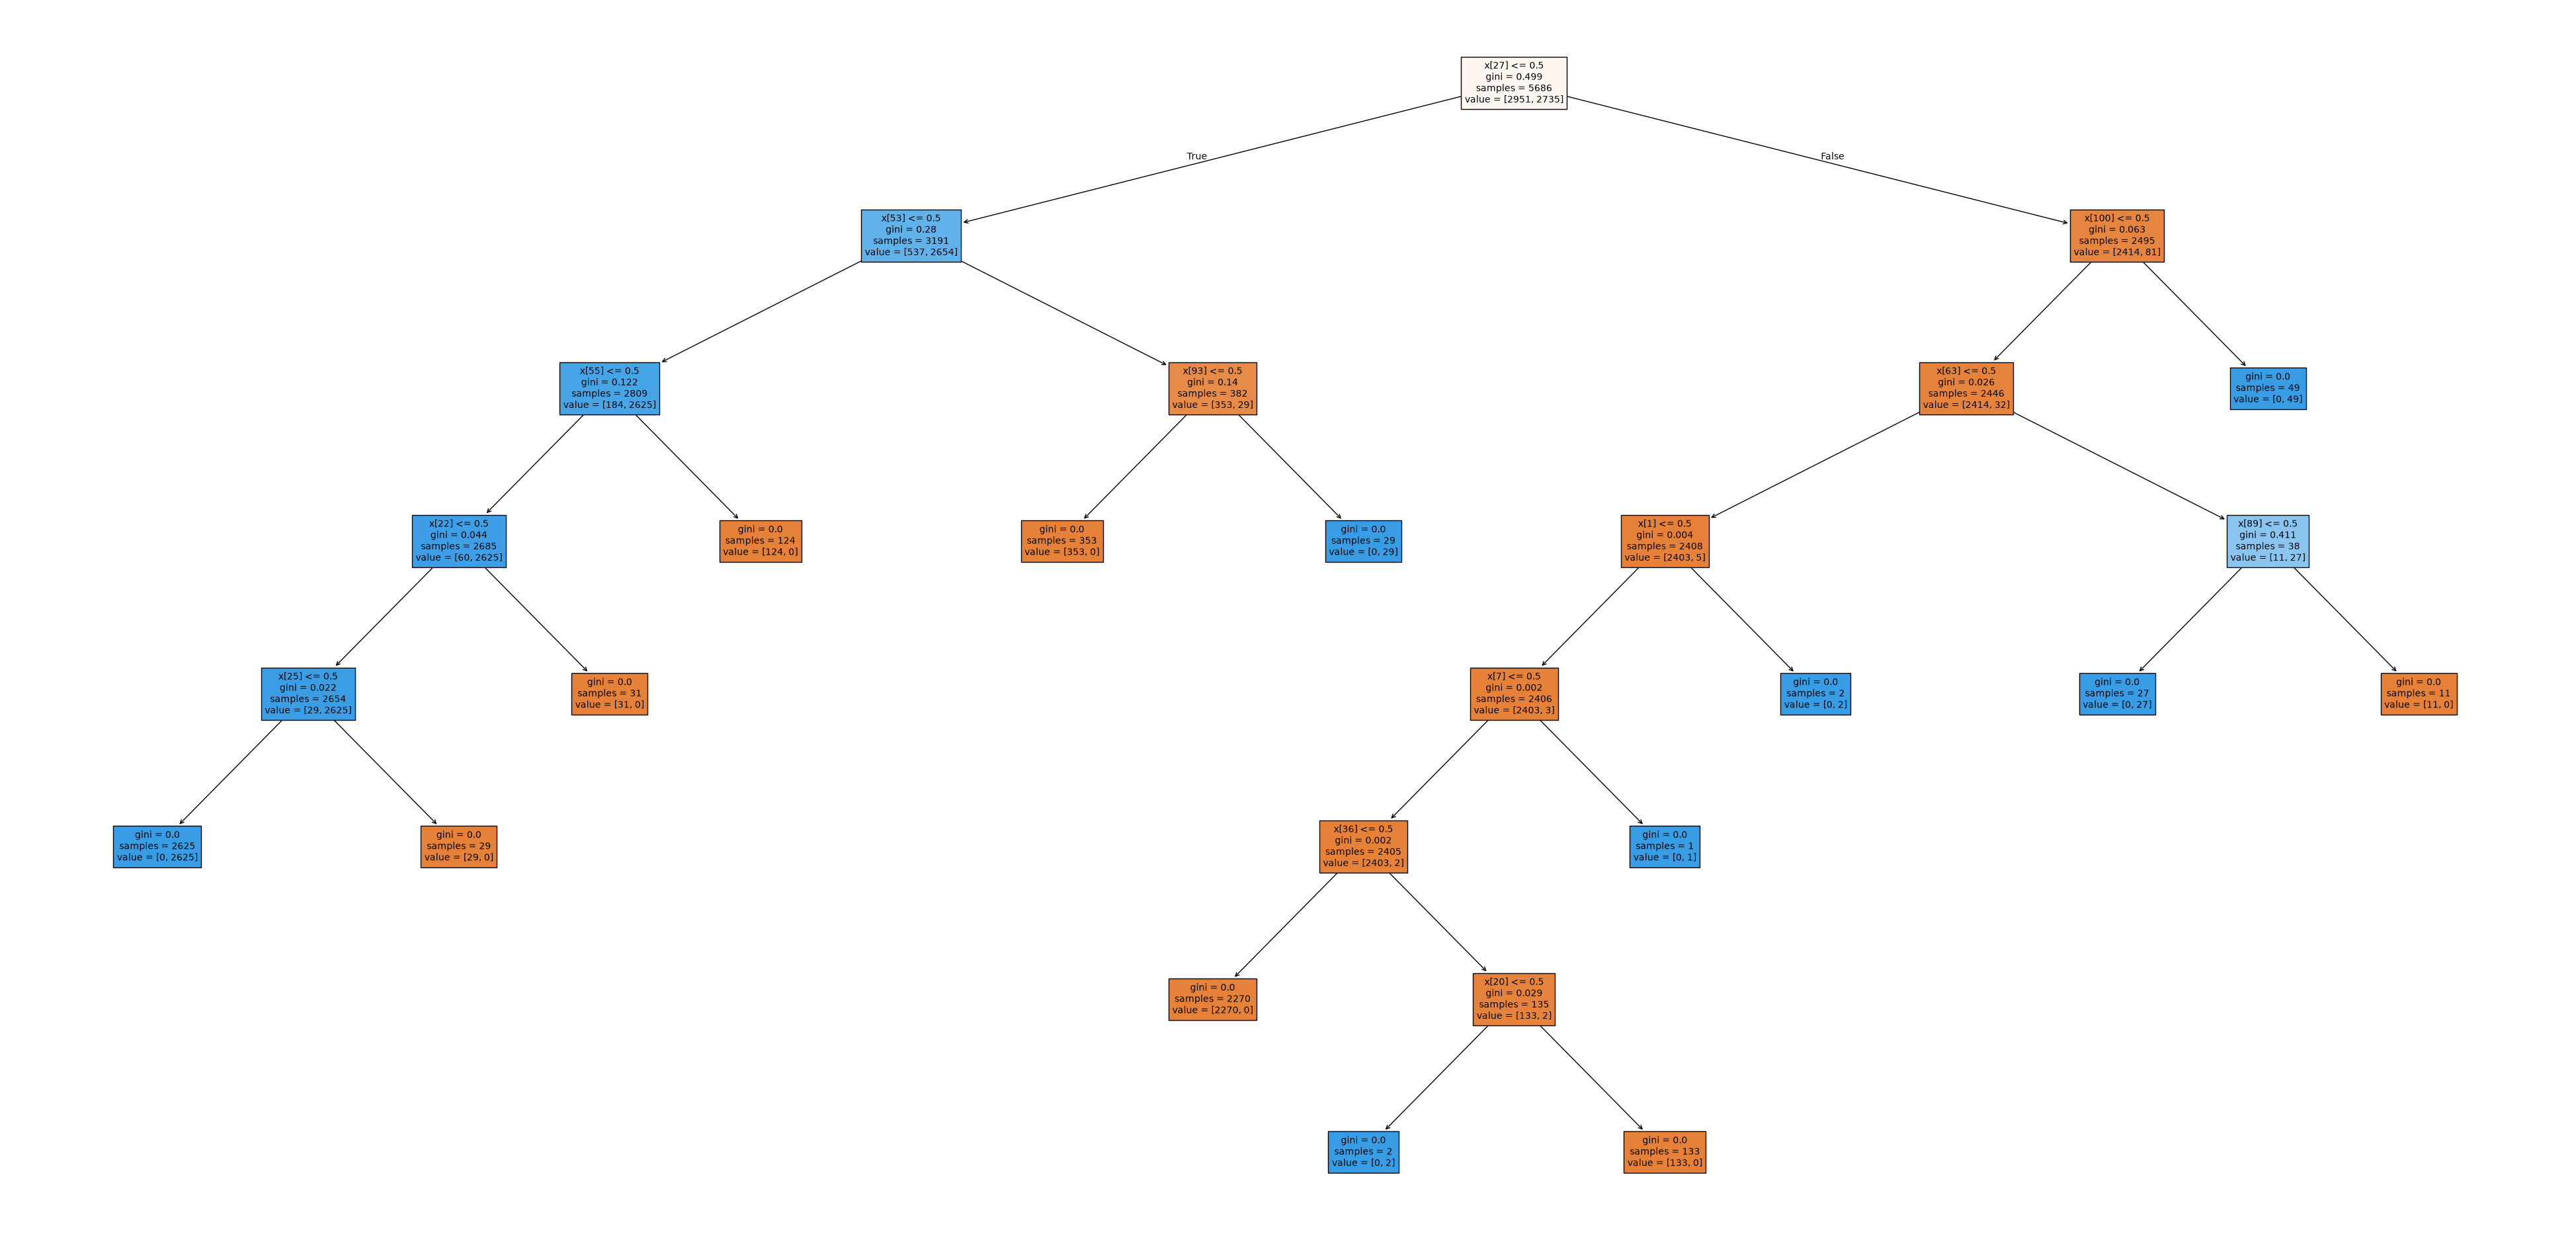

In [14]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Biểu diễn toàn bộ cây và lưu vào file ảnh
fig, ax = plt.subplots(figsize=(50, 24))
tree.plot_tree(cart, filled=True, fontsize=10)
plt.savefig('outputs/bai6_cart_tree', dpi=100)
plt.show()

Đinh Nhật Huyền Nhân - 6451071055


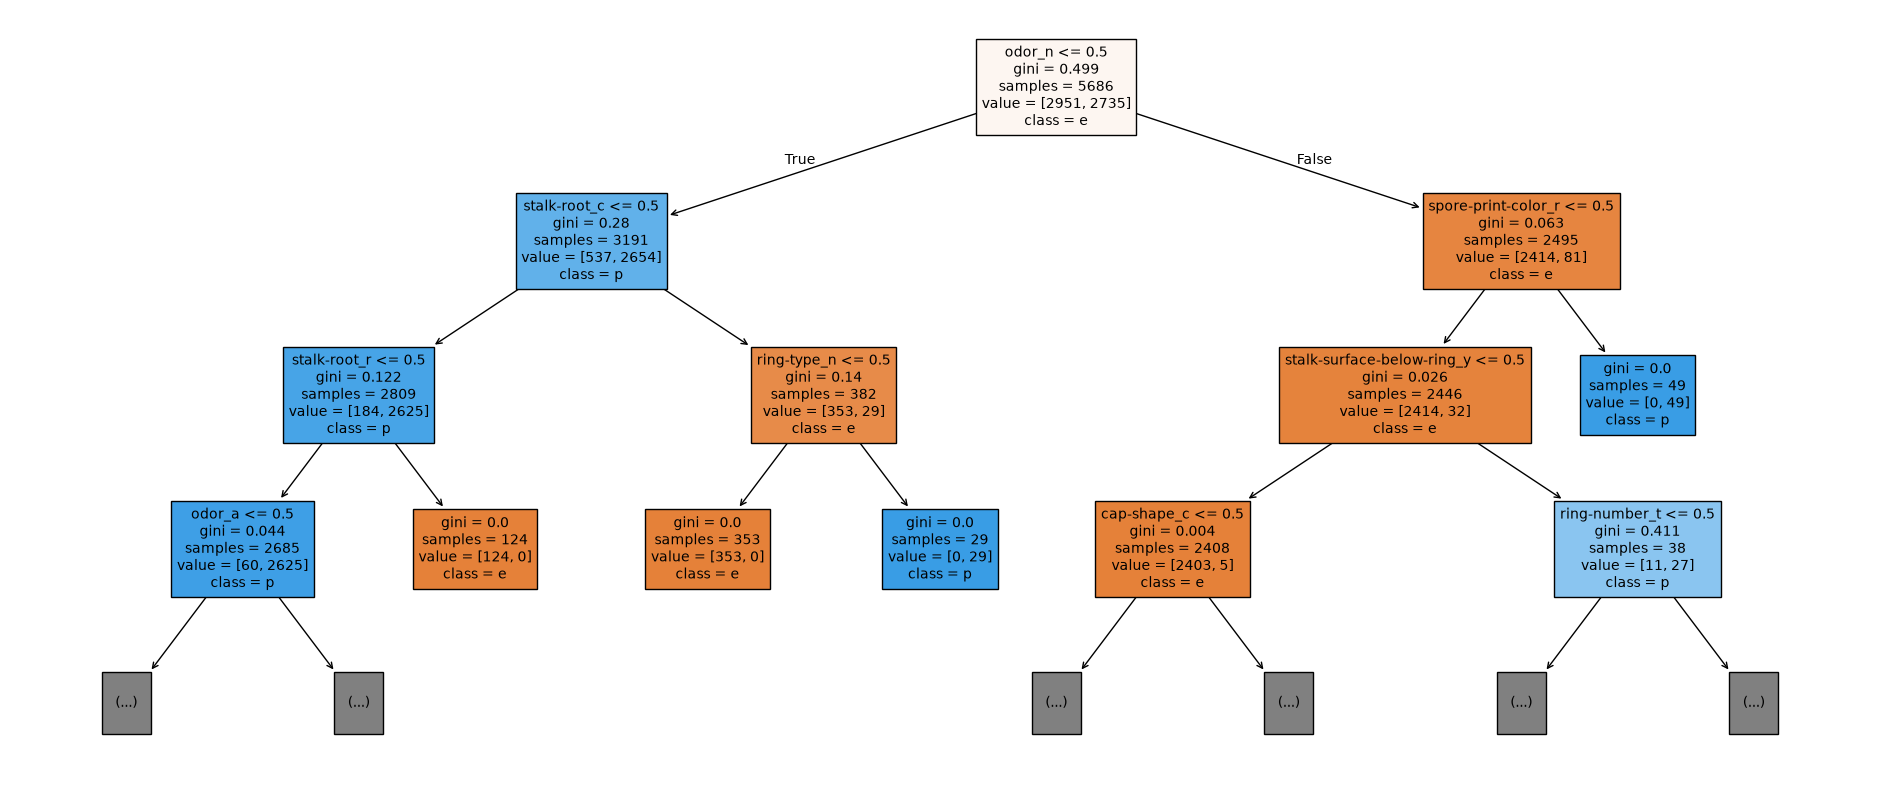

In [15]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Cây đầy đủ rất lớn nên vẽ thêm 3 tầng đầu với tên thuộc tính để dễ đọc
fig, ax = plt.subplots(figsize=(24, 10))
tree.plot_tree(cart, max_depth=3, feature_names=list(X_train.columns),
               class_names=[str(c) for c in cart.classes_], filled=True, fontsize=10)
plt.savefig('outputs/bai6_cart_tree_top3', dpi=100)
plt.show()

### Câu 9: Xây dựng mô hình Naïve Bayes

In [16]:
print("Đinh Nhật Huyền Nhân - 6451071055")
gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)

Đinh Nhật Huyền Nhân - 6451071055


In [17]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Model Accuracy, how often is the classifier correct?
bayes_score = metrics.accuracy_score(y_test, bayes_pred)
print("Accuracy:", bayes_score)
print("Report:", metrics.classification_report(y_test, bayes_pred, zero_division=0))

Đinh Nhật Huyền Nhân - 6451071055
Accuracy: 0.9643150123051681
Report:               precision    recall  f1-score   support

           e       1.00      0.93      0.96      1257
           p       0.93      1.00      0.96      1181

    accuracy                           0.96      2438
   macro avg       0.97      0.97      0.96      2438
weighted avg       0.97      0.96      0.96      2438



Đinh Nhật Huyền Nhân - 6451071055
[[1171   86]
 [   1 1180]]


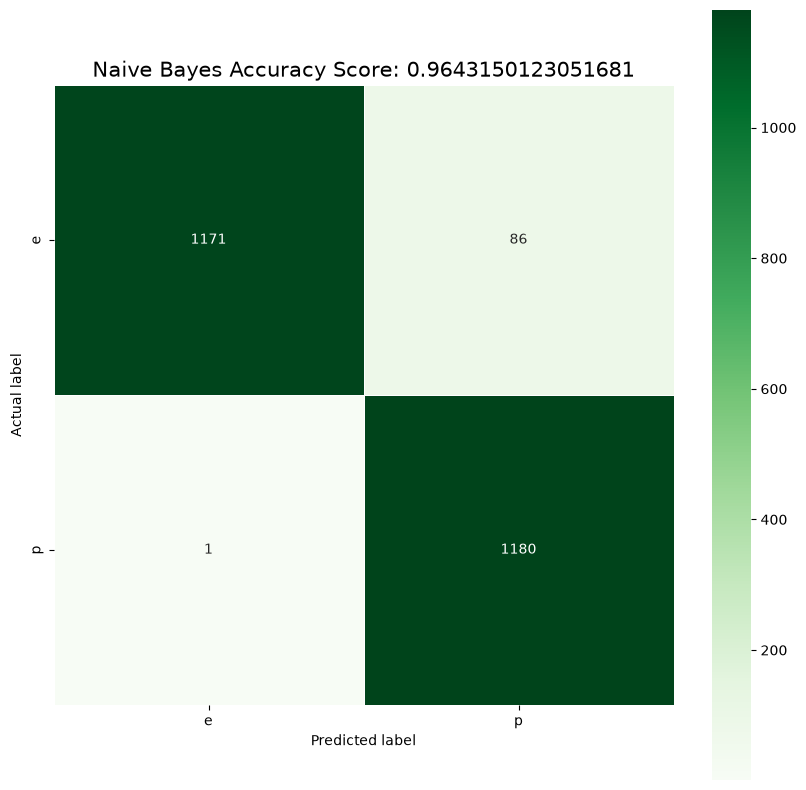

In [18]:
print("Đinh Nhật Huyền Nhân - 6451071055")
bayes_cm = metrics.confusion_matrix(y_test, bayes_pred, labels=gnb.classes_)
print(bayes_cm)

plt.figure(figsize=(10, 10))
sns.heatmap(bayes_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Greens',
            xticklabels=gnb.classes_, yticklabels=gnb.classes_)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title('Naive Bayes Accuracy Score: {0}'.format(bayes_score), size=15)
plt.show()

### Câu 10: So sánh kết quả của các mô hình

In [19]:
print("Đinh Nhật Huyền Nhân - 6451071055")
models = {'ID3': (id3, id3_pred), 'CART': (cart, cart_pred), 'Naive Bayes': (gnb, bayes_pred)}
rows = []
for name, (model, pred) in models.items():
    report = metrics.classification_report(y_test, pred, output_dict=True, zero_division=0)
    rows.append({'Model': name,
                 'Train acc': model.score(X_train, y_train),
                 'Test acc': report['accuracy'],
                 'Macro P': report['macro avg']['precision'],
                 'Macro R': report['macro avg']['recall'],
                 'Macro F1': report['macro avg']['f1-score'],
                 'Weighted F1': report['weighted avg']['f1-score']})
print(pd.DataFrame(rows).set_index('Model').round(4).to_string())

classes = sorted(y_test.unique())
print('\nĐộ chính xác (precision) theo từng lớp:')
print(pd.DataFrame({name: metrics.precision_score(y_test, pred, labels=classes, average=None, zero_division=0)
                    for name, (_, pred) in models.items()}, index=classes).round(4).to_string())
print('\nĐộ phủ (recall) theo từng lớp:')
print(pd.DataFrame({name: metrics.recall_score(y_test, pred, labels=classes, average=None, zero_division=0)
                    for name, (_, pred) in models.items()}, index=classes).round(4).to_string())

Đinh Nhật Huyền Nhân - 6451071055
             Train acc  Test acc  Macro P  Macro R  Macro F1  Weighted F1
Model                                                                    
ID3             1.0000    1.0000   1.0000   1.0000    1.0000       1.0000
CART            1.0000    1.0000   1.0000   1.0000    1.0000       1.0000
Naive Bayes     0.9683    0.9643   0.9656   0.9654    0.9643       0.9643

Độ chính xác (precision) theo từng lớp:


   ID3  CART  Naive Bayes
e  1.0   1.0       0.9991
p  1.0   1.0       0.9321

Độ phủ (recall) theo từng lớp:


   ID3  CART  Naive Bayes
e  1.0   1.0       0.9316
p  1.0   1.0       0.9992


**Nhận xét:** ID3 và CART đều đạt accuracy 1,0 trên tập kiểm thử với cây rất gọn (ID3 sâu 5 tầng, 11 nút lá; CART sâu 7 tầng, 14 nút lá). Vì kết quả kiểm thử cũng đạt 1,0 nên không có dấu hiệu quá khớp. Naïve Bayes đạt 0,9643, đoán nhầm 86 mẫu nấm ăn được thành nấm độc và 1 mẫu nấm độc thành ăn được. Với bài toán này, nhầm nấm độc thành ăn được là lỗi nguy hiểm nhất và hai cây không mắc lỗi đó trên tập kiểm thử, nên hai cây phù hợp hơn. GaussianNB giả định dữ liệu có phân phối chuẩn nên không thật sự phù hợp với các cột one-hot chỉ có giá trị 0 và 1.